In [2]:
import sys, json
sys.path.append("../src")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from features import RAW_FEATURES
from metrics import evaluate
from threshold import summarize
from drift import feature_psi
from monitor import label_free_report, check_rules

feat = pd.read_parquet("../data/processed/features.parquet")
champion = joblib.load("../models/champion_v1.joblib")
ref = json.load(open("../models/reference_stats.json"))
registry = json.load(open("../models/registry.json"))

THR = registry[0]["threshold"]
REVIEW_COST = registry[0]["review_cost"]
BASE_PR_AUC = registry[0]["val_metrics"]["pr_auc"]
print(THR, REVIEW_COST, BASE_PR_AUC)

tr = feat[feat.split == "train"]
va = feat[feat.split == "val"].copy()
prod = feat[feat.split == "prod"].copy()

va["score"] = champion.predict_proba(va[RAW_FEATURES])[:, 1]
prod["score"] = champion.predict_proba(prod[RAW_FEATURES])[:, 1]

ref_sample = tr[RAW_FEATURES].sample(20000, random_state=0)

0.0173 5.0 0.6295


In [3]:
half = tr[RAW_FEATURES].sample(frac=0.5, random_state=1)
print("Train half vs train reference, max PSI:", round(max(feature_psi(half, ref).values()), 4))

fp_val = feature_psi(va[RAW_FEATURES], ref)
pd.Series(fp_val).sort_values(ascending=False).head(8).round(3)

Train half vs train reference, max PSI: 0.0003


ProductCD    0.212
D10          0.193
D15          0.190
M9           0.152
M7           0.152
M8           0.151
D4           0.137
C10          0.127
dtype: float64

In [4]:
va["vweek"] = ((va["day"] - 60) // 7).astype(int)

quiet_rows, quiet_fp = [], []
for w in range(4):                      # days 60-88; the last 2 days are a partial week
    b = va[va.vweek == w]
    rep, fp, ks = label_free_report(b[RAW_FEATURES], b["score"].to_numpy(),
                                    ref, THR, ref_sample, cut=0.25)
    rep["pr_auc"] = evaluate(b["isFraud"], b["score"])["pr_auc"]
    quiet_rows.append({"val_week": w, **rep})
    quiet_fp.append(fp)

pd.DataFrame(quiet_rows).round(3)

,val_week,rows,alert_rate,score_psi,n_top_major,max_feature_psi,max_ks,pr_auc
0,0,23185,0.188,0.001,0,0.292,0.155,0.730
1,1,20739,0.194,0.000,0,0.225,0.137,0.656
2,2,20696,0.199,0.001,0,0.166,0.127,0.607
3,3,20901,0.192,0.001,0,0.266,0.142,0.544


In [5]:
top = ref["top_features"]
for cut in [0.25, 0.4]:
    counts = [sum(fp[c] > cut for c in top) for fp in quiet_fp]
    print(f"PSI cut {cut}: top-10 features above it, per validation week -> {counts}")

PSI cut 0.25: top-10 features above it, per validation week -> [0, 0, 0, 0]
PSI cut 0.4: top-10 features above it, per validation week -> [0, 0, 0, 0]


In [6]:
RULES = {"score_psi": 0.25,        # edit these two after reading the table above
         "n_top_major": 3,
         "feature_psi_cut": 0.25,
         "pr_auc_drop": 0.15}      # alert if known PR-AUC falls 15% below the validation value

json.dump(RULES, open("../models/monitor_rules.json", "w"), indent=2)
print(RULES, "| PR-AUC alert line:", round((1 - RULES["pr_auc_drop"]) * BASE_PR_AUC, 4))

{'score_psi': 0.25, 'n_top_major': 3, 'feature_psi_cut': 0.25, 'pr_auc_drop': 0.15} | PR-AUC alert line: 0.5351


In [7]:
rows, psi_rows, ks_rows = [], [], []

for w in range(12):
    b = prod[prod.batch == w]
    rep, fp, ks = label_free_report(b[RAW_FEATURES], b["score"].to_numpy(),
                                    ref, THR, ref_sample, cut=RULES["feature_psi_cut"])

    known = None
    if w >= 2:                                   # labels of week w-2 are now 14+ days old
        old = prod[prod.batch == w - 2]
        known = evaluate(old["isFraud"], old["score"])["pr_auc"]

    reasons = check_rules(rep, known, RULES, BASE_PR_AUC)
    s = summarize(b["isFraud"], b["TransactionAmt"], b["score"], THR, REVIEW_COST)

    rows.append({"batch": w, **rep,
                 "pr_auc_known": known,
                 "pr_auc_true": evaluate(b["isFraud"], b["score"])["pr_auc"],
                 "precision": s["precision"], "recall": s["recall"],
                 "net_benefit": s["net_benefit"],
                 "alert": bool(reasons), "reasons": ", ".join(reasons)})
    psi_rows.append(pd.Series(fp, name=w))
    ks_rows.append(pd.Series(ks, name=w))

mon = pd.DataFrame(rows)
psi_table = pd.DataFrame(psi_rows)
ks_table = pd.DataFrame(ks_rows)

mon.round(3)

,batch,rows,alert_rate,score_psi,n_top_major,max_feature_psi,max_ks,pr_auc_known,pr_auc_true,precision,recall,net_benefit,alert,reasons
0,0,28021,0.187,0.002,0,0.718,0.205,NaN,0.467,0.132,0.745,88883.15,False,
1,1,21888,0.202,0.002,1,0.626,0.201,NaN,0.476,0.132,0.790,76602.60,False,
2,2,20635,0.190,0.001,0,0.783,0.175,0.467,0.570,0.181,0.816,114660.03,True,performance drop
3,3,21004,0.216,0.005,0,0.737,0.152,0.476,0.614,0.192,0.832,106450.51,True,performance drop
4,4,23536,0.181,0.005,0,0.828,0.189,0.570,0.518,0.154,0.774,94129.58,False,
5,5,20337,0.180,0.004,0,0.898,0.210,0.614,0.543,0.159,0.794,68073.15,False,
6,6,18613,0.172,0.006,0,0.584,0.192,0.518,0.456,0.161,0.745,74643.89,True,performance drop
7,7,18239,0.166,0.008,0,0.679,0.211,0.543,0.417,0.149,0.722,56414.32,False,
8,8,20263,0.173,0.009,0,0.811,0.211,0.456,0.427,0.130,0.737,36702.66,True,performance drop
9,9,20967,0.177,0.007,0,0.914,0.216,0.417,0.496,0.126,0.739,38492.05,True,performance drop


In [8]:
mon.to_csv("../docs/day5_monitor_log.csv", index=False)
psi_table.to_csv("../docs/day5_psi_by_week.csv")
ks_table.to_csv("../docs/day5_ks_by_week.csv")

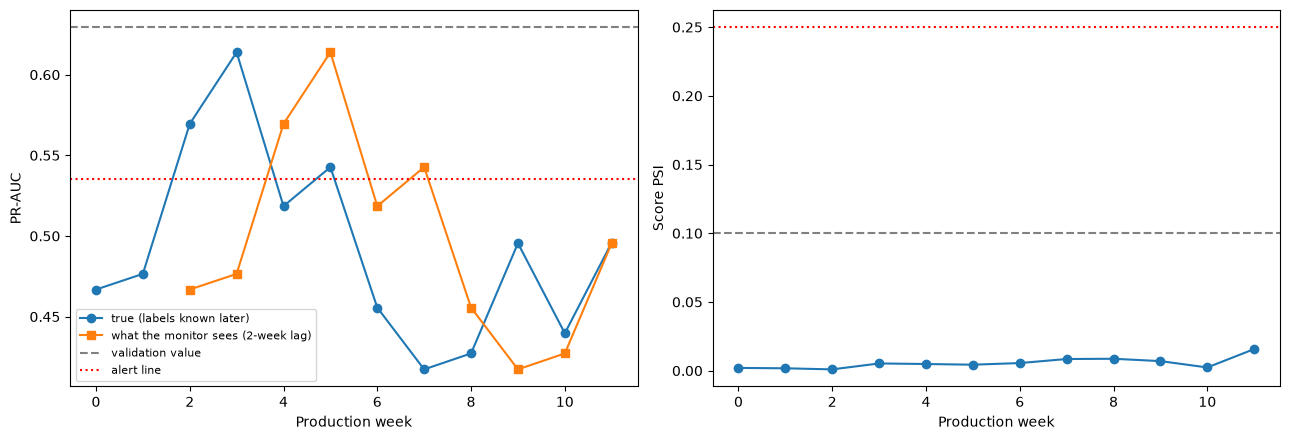

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(mon.batch, mon.pr_auc_true, marker="o", label="true (labels known later)")
ax[0].plot(mon.batch, mon.pr_auc_known, marker="s", label="what the monitor sees (2-week lag)")
ax[0].axhline(BASE_PR_AUC, ls="--", color="gray", label="validation value")
ax[0].axhline((1 - RULES["pr_auc_drop"]) * BASE_PR_AUC, ls=":", color="red", label="alert line")
ax[0].set_xlabel("Production week"); ax[0].set_ylabel("PR-AUC"); ax[0].legend(fontsize=8)

ax[1].plot(mon.batch, mon.score_psi, marker="o")
ax[1].axhline(0.1, ls="--", color="gray"); ax[1].axhline(0.25, ls=":", color="red")
ax[1].set_xlabel("Production week"); ax[1].set_ylabel("Score PSI")
plt.tight_layout(); plt.show()

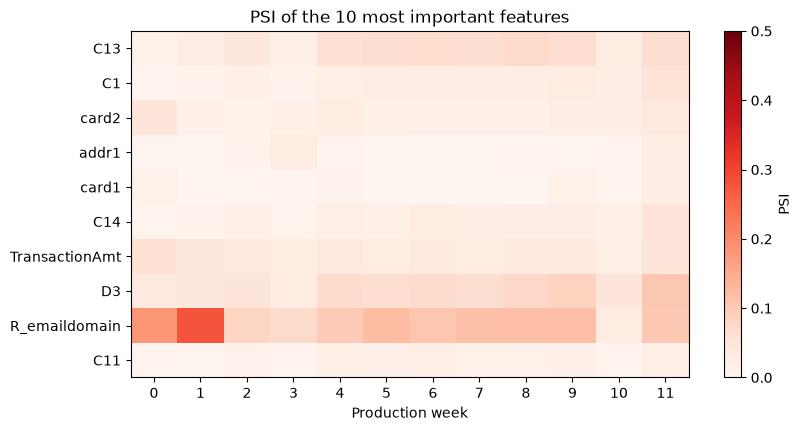

In [10]:
top = ref["top_features"]
plt.figure(figsize=(9, 4.5))
plt.imshow(psi_table[top].T.to_numpy(), aspect="auto", cmap="Reds", vmin=0, vmax=0.5)
plt.yticks(range(len(top)), top)
plt.xticks(range(12), range(12))
plt.xlabel("Production week"); plt.colorbar(label="PSI")
plt.title("PSI of the 10 most important features"); plt.show()

Replayed 12 production weeks with a 14-day label delay. Score PSI stayed below 0.02 and the alert rate stayed between 16.6% and 21.6%. Input drift among the 10 most important features was mild, but at least one other feature showed PSI of 0.58-0.91 every week (feature to be identified). True weekly PR-AUC ranged from 0.417 to 0.614 (validation: 0.6295; 12-week average about 0.49), lower in the second half than the first. Net benefit averaged about $72K per week versus about $81K per week on validation. The performance-drop rule (frozen at 15% below validation) fired in 7 of 10 evaluable weeks, so it is too sensitive for this level of week-to-week variation. The monitor saw the week-7 dip two weeks later because of the label delay.

In [11]:
# Which features drift most, and are they numeric or categorical?
top8 = psi_table.mean().sort_values(ascending=False).head(8)
print(pd.DataFrame({"avg_psi": top8.round(3),
                    "type": [ref["features"][c]["type"] for c in top8.index]}))

# Did the product mix change across periods?
f = feat[feat.split != "unused"]
print(pd.crosstab(f.split, f.ProductCD, normalize="index").round(3))
print(f.groupby(["split", "ProductCD"], observed=True)["isFraud"].mean().unstack().round(3))

           avg_psi type
M9           0.730  cat
M8           0.729  cat
M7           0.729  cat
D11          0.571  num
M2           0.563  cat
M3           0.563  cat
M1           0.562  cat
ProductCD    0.229  cat
ProductCD      W      H      C      S      R
split                                       
prod       0.800  0.026  0.115  0.021  0.038
train      0.651  0.106  0.117  0.020  0.106
val        0.799  0.025  0.120  0.016  0.040
ProductCD      W      H      C      S      R
split                                       
prod       0.021  0.073  0.126  0.052  0.053
train      0.020  0.032  0.100  0.039  0.023
val        0.021  0.128  0.122  0.107  0.091


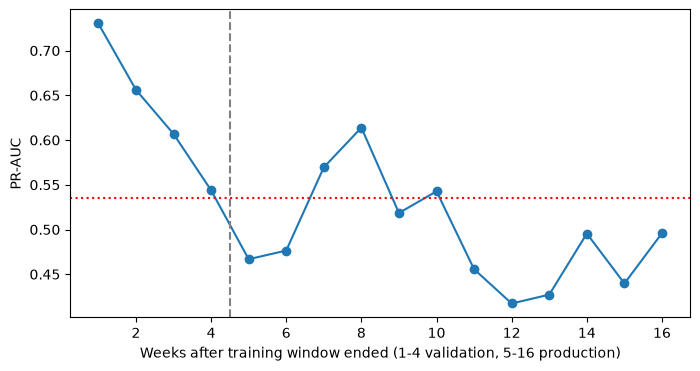

In [12]:
vw = pd.DataFrame(quiet_rows).pr_auc.tolist()
series = vw + mon.pr_auc_true.tolist()

plt.figure(figsize=(8, 4))
plt.plot(range(1, 17), series, marker="o")
plt.axvline(4.5, ls="--", color="gray")
plt.axhline(0.5351, ls=":", color="red")
plt.xlabel("Weeks after training window ended (1-4 validation, 5-16 production)")
plt.ylabel("PR-AUC"); plt.show()

PR-AUC fell from 0.730 in the first week after training to 0.467 in the fifth, partly recovered to 0.614 in week 8, and stayed at 0.42-0.54 in weeks 9-16. PSI against the training window was high (0.56-0.73) for M1-M3, M7-M9 and D11 in every production week, while the top-10 features and the score distribution stayed stable. The ProductCD mix changed between training and validation (W 65% to 80%, H 11% to 3%, R 11% to 4%) and then stayed constant. Fraud rates for products H, S and R rose from about 2-4% in training to about 9-13% in validation, easing to 5-7% in production. These are observations and I have not shown that they cause the PR-AUC decline.

In [13]:
f = feat[feat.split != "unused"]

print("Share of blanks by period:")
print(f.groupby("split")[["M1", "M7", "M9", "D11"]].agg(lambda s: s.isna().mean()).round(3))

print("\nM9 blank share by product (train / val / prod):")
print(f.groupby(["split", "ProductCD"], observed=True)["M9"].apply(lambda s: s.isna().mean()).unstack().round(2))

print("\nPR-AUC by product (compare val vs prod within the same product):")
for name, d in [("val", va), ("prod", prod)]:
    for p in ["W", "C", "H", "S", "R"]:
        g = d[d.ProductCD == p]
        print(name, p, "rows", len(g), "frauds", int(g.isFraud.sum()),
              "pr_auc", evaluate(g.isFraud, g.score)["pr_auc"])

Share of blanks by period:
          M1     M7     M9    D11
split                            
prod   0.287  0.402  0.402  0.308
train  0.651  0.804  0.804  0.663
val    0.526  0.631  0.631  0.529

M9 blank share by product (train / val / prod):
ProductCD     W    H    C    S    R
split                              
prod       0.25  1.0  1.0  1.0  1.0
train      0.70  1.0  1.0  1.0  1.0
val        0.54  1.0  1.0  1.0  1.0

PR-AUC by product (compare val vs prod within the same product):
val W rows 73295 frauds 1571 pr_auc 0.313
val C rows 11048 frauds 1345 pr_auc 0.8539
val H rows 2327 frauds 298 pr_auc 0.6881
val S rows 1464 frauds 156 pr_auc 0.8056
val R rows 3634 frauds 330 pr_auc 0.8267
prod W rows 203794 frauds 4178 pr_auc 0.131
prod C rows 29330 frauds 3707 pr_auc 0.7682
prod H rows 6558 frauds 479 pr_auc 0.6372
prod S rows 5286 frauds 275 pr_auc 0.5023
prod R rows 9726 frauds 512 pr_auc 0.7874


M1-M3, M7-M9 and D11 are populated far more often later in time: the share of blank M9 rose from 80% (train) to 63% (val) to 40% (prod) overall. M columns exist only for product W, and within W the blank share fell from 70% to 54% to 25%. Product mix explains only about a quarter of the train-to-val change. PR-AUC fell much more for product W (0.313 to 0.131, flat 2.1% fraud rate) than for product C (0.854 to 0.768), suggesting the decline is concentrated where the M and D11 features changed. This is an observed association, not a demonstrated cause.